In [1]:
from pathlib import Path
import pandas as pd

# Find the project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

movies_path = DATA_DIR / "movies.csv"
ratings_path = DATA_DIR / "ratings.csv"

assert movies_path.exists(), f"File not found: {movies_path}"
assert ratings_path.exists(), f"File not found: {ratings_path}"

movies = pd.read_csv(movies_path)
ratings = pd.read_csv(ratings_path)

print("Project root:", PROJECT_ROOT)
print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)

print("\nMovies columns:")
print(movies.columns.tolist())

print("\nRatings columns:")
print(ratings.columns.tolist())

print("\nMissing values in movies:")
print(movies.isna().sum())

print("\nMissing values in ratings:")
print(ratings.isna().sum())

print("\nUnique users:", ratings["userId"].nunique())
print("Unique rated movies:", ratings["movieId"].nunique())

print("\nRating range:")
print(ratings["rating"].min(), "to", ratings["rating"].max())

print(
    "\nDuplicate movie IDs:",
    movies["movieId"].duplicated().sum()
)

print(
    "Duplicate user-movie pairs:",
    ratings.duplicated(["userId", "movieId"]).sum()
)

missing_movie_ids = set(ratings["movieId"]) - set(movies["movieId"])
print("Rated movie IDs missing from movies.csv:", len(missing_movie_ids))

Project root: d:\Projects\book-movie-recommender
Movies shape: (9742, 3)
Ratings shape: (100836, 4)

Movies columns:
['movieId', 'title', 'genres']

Ratings columns:
['userId', 'movieId', 'rating', 'timestamp']

Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Unique users: 610
Unique rated movies: 9724

Rating range:
0.5 to 5.0

Duplicate movie IDs: 0
Duplicate user-movie pairs: 0
Rated movie IDs missing from movies.csv: 0


In [2]:
print(movies.shape)
print(ratings.shape)

(9742, 3)
(100836, 4)


In [3]:
# Basic exploratory data analysis

print("=== Rating statistics ===")
print(ratings["rating"].describe())

print("\n=== Rating distribution ===")
print(ratings["rating"].value_counts().sort_index())

print("\n=== Ratings per user ===")
ratings_per_user = ratings.groupby("userId").size()
print(ratings_per_user.describe())

print("\n=== Ratings per movie ===")
ratings_per_movie = ratings.groupby("movieId").size()
print(ratings_per_movie.describe())

print("\n=== Most rated movies ===")
most_rated = (
    ratings.groupby("movieId")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("rating_count")
    .reset_index()
    .merge(movies, on="movieId", how="left")
)

print(most_rated[["title", "genres", "rating_count"]].to_string(index=False))

print("\n=== Average rating by genre-independent catalog ===")
movie_stats = (
    ratings.groupby("movieId")["rating"]
    .agg(["count", "mean"])
    .reset_index()
    .merge(movies, on="movieId", how="left")
)

print(
    movie_stats.sort_values("count", ascending=False)
    [["title", "count", "mean"]]
    .head(10)
    .to_string(index=False)
)

=== Rating statistics ===
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

=== Rating distribution ===
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

=== Ratings per user ===
count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64

=== Ratings per movie ===
count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64

=== Most rated movies ===
                                    title                           genres  rating_count
                      Forrest Gump

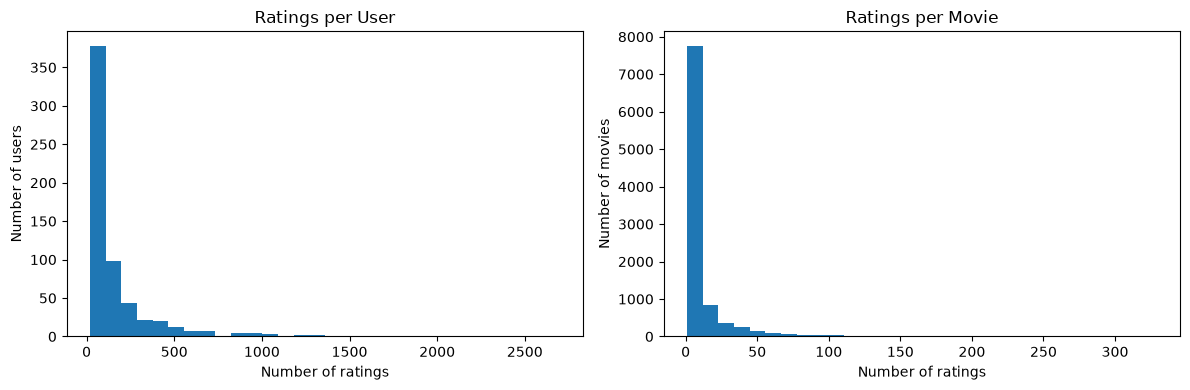

Users with 10 or fewer ratings: 0
Movies with fewer than 5 ratings: 6074
Median ratings per user: 70.5
Median ratings per movie: 3.0


In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ratings_per_user = ratings.groupby("userId").size()
ratings_per_movie = ratings.groupby("movieId").size()

axes[0].hist(ratings_per_user, bins=30)
axes[0].set_title("Ratings per User")
axes[0].set_xlabel("Number of ratings")
axes[0].set_ylabel("Number of users")

axes[1].hist(ratings_per_movie, bins=30)
axes[1].set_title("Ratings per Movie")
axes[1].set_xlabel("Number of ratings")
axes[1].set_ylabel("Number of movies")

plt.tight_layout()
plt.show()

print("Users with 10 or fewer ratings:",
      (ratings_per_user <= 10).sum())

print("Movies with fewer than 5 ratings:",
      (ratings_per_movie < 5).sum())

print("Median ratings per user:",
      ratings_per_user.median())

print("Median ratings per movie:",
      ratings_per_movie.median())

In [5]:
# Measure sparsity of the user-item rating matrix

n_users = ratings["userId"].nunique()
n_movies = movies["movieId"].nunique()
n_ratings = len(ratings)

total_possible = n_users * n_movies
density = n_ratings / total_possible
sparsity = 1 - density

print("Users:", n_users)
print("Movies:", n_movies)
print("Observed ratings:", n_ratings)
print("Possible user-movie pairs:", total_possible)
print(f"Matrix density: {density:.2%}")
print(f"Matrix sparsity: {sparsity:.2%}")

Users: 610
Movies: 9742
Observed ratings: 100836
Possible user-movie pairs: 5942620
Matrix density: 1.70%
Matrix sparsity: 98.30%


In [6]:
# Baseline: rank movies by average rating,
# while requiring a minimum number of ratings.

movie_stats = (
    ratings.groupby("movieId")["rating"]
    .agg(["count", "mean"])
    .reset_index()
    .rename(columns={
        "count": "rating_count",
        "mean": "avg_rating"
    })
)

movie_stats = movie_stats.merge(
    movies[["movieId", "title", "genres"]],
    on="movieId",
    how="left"
)

MIN_RATINGS = 50

popular_movies = (
    movie_stats[movie_stats["rating_count"] >= MIN_RATINGS]
    .sort_values(
        ["avg_rating", "rating_count"],
        ascending=[False, False]
    )
    .head(10)
)

print("Top 10 movies (minimum 50 ratings):")
print(
    popular_movies[
        ["title", "genres", "rating_count", "avg_rating"]
    ].to_string(index=False)
)

print("\nMovies eligible for ranking:",
      (movie_stats["rating_count"] >= MIN_RATINGS).sum())

Top 10 movies (minimum 50 ratings):
                                                                      title                      genres  rating_count  avg_rating
                                           Shawshank Redemption, The (1994)                 Crime|Drama           317    4.429022
                                                      Godfather, The (1972)                 Crime|Drama           192    4.289062
                                                          Fight Club (1999) Action|Crime|Drama|Thriller           218    4.272936
                                                      Cool Hand Luke (1967)                       Drama            57    4.271930
Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964)                  Comedy|War            97    4.268041
                                                         Rear Window (1954)            Mystery|Thriller            84    4.261905
                                             Godfather

In [7]:
from sklearn.model_selection import train_test_split
import pandas as pd

train_parts = []
test_parts = []

for user_id, user_ratings in ratings.groupby("userId"):
    if len(user_ratings) < 2:
        train_parts.append(user_ratings)
        continue

    user_train, user_test = train_test_split(
        user_ratings,
        test_size=0.2,
        random_state=42
    )

    train_parts.append(user_train)
    test_parts.append(user_test)

train_ratings = pd.concat(train_parts).reset_index(drop=True)
test_ratings = pd.concat(test_parts).reset_index(drop=True)

print("Training ratings:", len(train_ratings))
print("Test ratings:", len(test_ratings))
print("Users in training:", train_ratings["userId"].nunique())
print("Users in test:", test_ratings["userId"].nunique())
print(
    "User overlap:",
    len(set(train_ratings["userId"]) & set(test_ratings["userId"]))
)

Training ratings: 80419
Test ratings: 20417
Users in training: 610
Users in test: 610
User overlap: 610


In [8]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# User-item matrix built from training data only
train_matrix = train_ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

# Fill missing entries with 0 only for similarity calculation.
# A zero here means "not rated" in this temporary matrix,
# not an actual user rating.
filled_matrix = train_matrix.fillna(0)

# Similarity between users
user_similarity = cosine_similarity(filled_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=train_matrix.index,
    columns=train_matrix.index
)

print("User-item matrix shape:", train_matrix.shape)
print("User similarity matrix shape:", user_similarity_df.shape)
print("\nExample user similarities:")
print(user_similarity_df.iloc[:5, :5].round(3))

User-item matrix shape: (610, 8965)
User similarity matrix shape: (610, 610)

Example user similarities:
userId      1      2      3      4      5
userId                                   
1       1.000  0.000  0.077  0.126  0.099
2       0.000  1.000  0.000  0.000  0.022
3       0.077  0.000  1.000  0.000  0.006
4       0.126  0.000  0.000  1.000  0.128
5       0.099  0.022  0.006  0.128  1.000


In [9]:
def recommend_movies(user_id, n_recommendations=10, k_neighbors=20):
    if user_id not in train_matrix.index:
        raise ValueError(f"User {user_id} is not present in training data.")

    # Similar users, excluding the target user
    similarities = user_similarity_df.loc[user_id].drop(user_id)
    neighbors = similarities.nlargest(k_neighbors)

    # Ratings given by similar users
    neighbor_ratings = train_matrix.loc[neighbors.index]

    # Only use ratings that actually exist
    weighted_ratings = neighbor_ratings.mul(neighbors, axis=0)

    # Sum similarities only for neighbors who rated each movie
    rated_mask = neighbor_ratings.notna()
    denominators = rated_mask.mul(neighbors, axis=0).sum(axis=0)

    numerators = weighted_ratings.sum(axis=0, skipna=True)
    predictions = numerators.div(denominators.replace(0, np.nan))

    # Exclude movies the user has already rated in training data
    already_rated = train_matrix.loc[user_id].dropna().index
    predictions = predictions.drop(index=already_rated, errors="ignore")

    # Rank and return top recommendations
    top_predictions = predictions.dropna().nlargest(n_recommendations)

    results = top_predictions.rename("predicted_rating").reset_index()
    results = results.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )

    return results[["movieId", "title", "genres", "predicted_rating"]]


recommendations = recommend_movies(user_id=1, n_recommendations=10)
print(recommendations.to_string(index=False))

 movieId                                            title                        genres  predicted_rating
     187                                Party Girl (1995)                        Comedy               5.0
     232      Eat Drink Man Woman (Yin shi nan nu) (1994)          Comedy|Drama|Romance               5.0
     281                             Nobody's Fool (1994)          Comedy|Drama|Romance               5.0
     306 Three Colors: Red (Trois couleurs: Rouge) (1994)                         Drama               5.0
     348                     Bullets Over Broadway (1994)                        Comedy               5.0
     456                                     Fresh (1994)          Crime|Drama|Thriller               5.0
     514                                  Ref, The (1994)                        Comedy               5.0
     633                           Denise Calls Up (1995)                        Comedy               5.0
     724                                Craft,

In [10]:
user_id = 1
k_neighbors = 20

similarities = user_similarity_df.loc[user_id].drop(user_id)
neighbors = similarities.nlargest(k_neighbors)

neighbor_ratings = train_matrix.loc[neighbors.index]
weighted_ratings = neighbor_ratings.mul(neighbors, axis=0)

rated_mask = neighbor_ratings.notna()
denominators = rated_mask.mul(neighbors, axis=0).sum(axis=0)
numerators = weighted_ratings.sum(axis=0, skipna=True)

predictions = numerators.div(denominators.replace(0, np.nan))

already_rated = train_matrix.loc[user_id].dropna().index
predictions = predictions.drop(index=already_rated, errors="ignore")

top_ids = predictions.dropna().nlargest(10).index

diagnostics = pd.DataFrame({
    "movieId": top_ids,
    "predicted_rating": predictions.loc[top_ids].values,
    "neighbor_count": rated_mask[top_ids].sum(axis=0).values,
    "similarity_weight_sum": denominators.loc[top_ids].values,
})

diagnostics = diagnostics.merge(
    movies[["movieId", "title"]],
    on="movieId",
    how="left"
)

print(diagnostics.to_string(index=False))

 movieId  predicted_rating  neighbor_count  similarity_weight_sum                                            title
     187               5.0               1               0.240821                                Party Girl (1995)
     232               5.0               1               0.262294      Eat Drink Man Woman (Yin shi nan nu) (1994)
     281               5.0               1               0.262294                             Nobody's Fool (1994)
     306               5.0               1               0.250215 Three Colors: Red (Trois couleurs: Rouge) (1994)
     348               5.0               2               0.533379                     Bullets Over Broadway (1994)
     456               5.0               1               0.250215                                     Fresh (1994)
     514               5.0               2               0.537913                                  Ref, The (1994)
     633               5.0               1               0.240821               

In [11]:
# بررسی تعداد همسایه‌هایی که با کاربر 1 شباهت دارند
user_id = 1

similarities = user_similarity_df.loc[user_id].drop(user_id)

print("Top 10 similar users:")
print(similarities.nlargest(10))

print("\nSimilarity statistics:")
print(similarities.describe())

print("\nNumber of users with similarity > 0:")
print((similarities > 0).sum())

Top 10 similar users:
userId
368    0.301938
266    0.297092
57     0.296645
313    0.290049
330    0.287225
91     0.279521
45     0.271869
480    0.271086
597    0.262294
217    0.257501
Name: 1, dtype: float64

Similarity statistics:
count    609.000000
mean       0.104108
std        0.063076
min        0.000000
25%        0.057893
50%        0.092274
75%        0.136521
max        0.301938
Name: 1, dtype: float64

Number of users with similarity > 0:
598


In [12]:
min_neighbors = 3

valid_predictions = predictions[
    rated_mask.sum(axis=0) >= min_neighbors
]

top_movies = valid_predictions.nlargest(10)

results = top_movies.rename("predicted_rating").reset_index()

results = results.merge(
    movies[["movieId", "title", "genres"]],
    on="movieId",
    how="left"
)

print(results.to_string(index=False))

 movieId  predicted_rating                       title                         genres
    2502          4.799313         Office Space (1999)                   Comedy|Crime
    1203          4.755123         12 Angry Men (1957)                          Drama
    1235          4.748507     Harold and Maude (1971)           Comedy|Drama|Romance
    7387          4.701835     Dawn of the Dead (1978)            Action|Drama|Horror
    1248          4.688223        Touch of Evil (1958)       Crime|Film-Noir|Thriller
    1283          4.685868            High Noon (1952)                  Drama|Western
    2352          4.680325       Big Chill, The (1983)                   Comedy|Drama
    3060          4.676021     Commitments, The (1991)           Comedy|Drama|Musical
    2186          4.674249 Strangers on a Train (1951) Crime|Drama|Film-Noir|Thriller
    1719          4.673768 Sweet Hereafter, The (1997)                          Drama


In [13]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual_ratings = []
predicted_ratings = []

for row in test_ratings.itertuples(index=False):
    user_id = row.userId
    movie_id = row.movieId
    actual_rating = row.rating

    if user_id not in train_matrix.index:
        continue

    if movie_id not in train_matrix.columns:
        continue

    similarities = user_similarity_df.loc[user_id].drop(user_id)
    neighbors = similarities.nlargest(20)

    neighbor_ratings = train_matrix.loc[neighbors.index, movie_id]
    valid = neighbor_ratings.notna()

    if valid.sum() < 3:
        continue

    neighbor_weights = neighbors.loc[valid.index[valid]]
    ratings = neighbor_ratings.loc[valid]

    denominator = neighbor_weights.sum()

    if denominator == 0:
        continue

    prediction = (ratings * neighbor_weights).sum() / denominator

    actual_ratings.append(actual_rating)
    predicted_ratings.append(prediction)

print("Evaluated ratings:", len(actual_ratings))
print("MAE:", round(mean_absolute_error(actual_ratings, predicted_ratings), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(actual_ratings, predicted_ratings)), 4))

Evaluated ratings: 13562
MAE: 0.7276
RMSE: 0.942


BASE MODLE 

In [14]:
# Baseline: رتبه‌بندی فیلم‌ها بر اساس میانگین امتیاز
baseline_movies = (
    train_ratings
    .groupby("movieId")["rating"]
    .agg(["mean", "count"])
    .reset_index()
)

# حذف فیلم‌هایی که کمتر از 50 امتیاز در داده‌های آموزش دارند
baseline_movies = baseline_movies[
    baseline_movies["count"] >= 50
].copy()

# اضافه کردن عنوان فیلم‌ها
baseline_movies = baseline_movies.merge(
    movies[["movieId", "title", "genres"]],
    on="movieId",
    how="left"
)

# مرتب‌سازی بر اساس میانگین امتیاز
baseline_movies = baseline_movies.sort_values(
    "mean", ascending=False
)

print("Number of eligible movies:", len(baseline_movies))
print(
    baseline_movies[
        ["title", "genres", "mean", "count"]
    ].head(10).to_string(index=False)
)

Number of eligible movies: 323
                                                                         title                                  genres     mean  count
                                              Shawshank Redemption, The (1994)                             Crime|Drama 4.415663    249
                                                    Princess Bride, The (1987) Action|Adventure|Comedy|Fantasy|Romance 4.285714    105
                                                            Rear Window (1954)                        Mystery|Thriller 4.279412     68
                                                       Dark Knight, The (2008)                 Action|Crime|Drama|IMAX 4.269231    117
                                                         Godfather, The (1972)                             Crime|Drama 4.266234    154
                                                             Fight Club (1999)             Action|Crime|Drama|Thriller 4.257396    169
                        

In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_test = test_ratings.merge(
    train_ratings.groupby("movieId")["rating"].mean().rename("baseline_prediction"),
    on="movieId",
    how="inner"
)

baseline_actual = baseline_test["rating"]
baseline_predicted = baseline_test["baseline_prediction"]

baseline_mae = mean_absolute_error(
    baseline_actual, baseline_predicted
)

baseline_rmse = np.sqrt(
    mean_squared_error(baseline_actual, baseline_predicted)
)

print("Evaluated ratings:", len(baseline_test))
print("Baseline MAE:", round(baseline_mae, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))

Evaluated ratings: 19590
Baseline MAE: 0.7545
Baseline RMSE: 0.976


In [16]:
print("train_ratings type:", type(train_ratings))
print("train_ratings columns:", getattr(train_ratings, "columns", "No columns"))
print("train_ratings shape:", train_ratings.shape)

print("\ntest_ratings type:", type(test_ratings))
print("test_ratings columns:", getattr(test_ratings, "columns", "No columns"))

train_ratings type: <class 'pandas.DataFrame'>
train_ratings columns: Index(['userId', 'movieId', 'rating', 'timestamp'], dtype='str')
train_ratings shape: (80419, 4)

test_ratings type: <class 'pandas.DataFrame'>
test_ratings columns: Index(['userId', 'movieId', 'rating', 'timestamp'], dtype='str')


In [17]:
from sklearn.metrics.pairwise import cosine_similarity

# Create the user-movie rating matrix
train_matrix = train_ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

# Fill missing ratings with zero
filled_matrix = train_matrix.fillna(0)

# Calculate cosine similarity between users
user_similarity = cosine_similarity(filled_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=train_matrix.index,
    columns=train_matrix.index
)

print("Training matrix shape:", train_matrix.shape)
print("Similarity matrix shape:", user_similarity_df.shape)

Training matrix shape: (610, 8965)
Similarity matrix shape: (610, 610)


In [18]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Reload ratings if necessary
ratings = pd.read_csv(DATA_DIR / "ratings.csv")

train_parts = []
test_parts = []

for user_id, group in ratings.groupby("userId"):
    if len(group) < 2:
        train_parts.append(group)
        continue

    user_train, user_test = train_test_split(
        group,
        test_size=0.2,
        random_state=42
    )

    train_parts.append(user_train)
    test_parts.append(user_test)

train_ratings = pd.concat(train_parts).sort_index()
test_ratings = pd.concat(test_parts).sort_index()

print("Train type:", type(train_ratings))
print("Train shape:", train_ratings.shape)
print("Train columns:", train_ratings.columns.tolist())

print("Test type:", type(test_ratings))
print("Test shape:", test_ratings.shape)
print("Test columns:", test_ratings.columns.tolist())

Train type: <class 'pandas.DataFrame'>
Train shape: (80419, 4)
Train columns: ['userId', 'movieId', 'rating', 'timestamp']
Test type: <class 'pandas.DataFrame'>
Test shape: (20417, 4)
Test columns: ['userId', 'movieId', 'rating', 'timestamp']


In [19]:
from sklearn.metrics.pairwise import cosine_similarity

train_matrix = train_ratings.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

filled_matrix = train_matrix.fillna(0)

user_similarity = cosine_similarity(filled_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=train_matrix.index,
    columns=train_matrix.index
)

print("Training matrix shape:", train_matrix.shape)
print("Similarity matrix shape:", user_similarity_df.shape)

Training matrix shape: (610, 8965)
Similarity matrix shape: (610, 610)


In [20]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

movie_means = train_ratings.groupby("movieId")["rating"].mean()

actual_ratings = []
baseline_predictions = []
cf_predictions = []

for row in test_ratings.itertuples(index=False):
    user_id = row.userId
    movie_id = row.movieId
    actual_rating = row.rating

    if movie_id not in train_matrix.columns:
        continue

    baseline_prediction = movie_means.get(movie_id)
    if pd.isna(baseline_prediction):
        continue

    similarities = user_similarity_df.loc[user_id].drop(user_id)
    neighbors = similarities.nlargest(20)

    neighbor_ratings = train_matrix.loc[neighbors.index, movie_id]
    valid = neighbor_ratings.notna()

    if valid.sum() < 3:
        continue

    weights = neighbors.loc[valid[valid].index]
    ratings_for_movie = neighbor_ratings.loc[valid]

    if weights.sum() <= 0:
        continue

    cf_prediction = (ratings_for_movie * weights).sum() / weights.sum()

    actual_ratings.append(actual_rating)
    baseline_predictions.append(baseline_prediction)
    cf_predictions.append(cf_prediction)

print("Common evaluated ratings:", len(actual_ratings))
print("Baseline MAE:", round(mean_absolute_error(actual_ratings, baseline_predictions), 4))
print("Baseline RMSE:", round(np.sqrt(mean_squared_error(actual_ratings, baseline_predictions)), 4))
print("Collaborative Filtering MAE:", round(mean_absolute_error(actual_ratings, cf_predictions), 4))
print("Collaborative Filtering RMSE:", round(np.sqrt(mean_squared_error(actual_ratings, cf_predictions)), 4))


Common evaluated ratings: 13562
Baseline MAE: 0.7175
Baseline RMSE: 0.9252
Collaborative Filtering MAE: 0.7276
Collaborative Filtering RMSE: 0.942


### Evaluation Results and Comparison

The baseline model, which predicts ratings using the average rating of each movie in the training set, outperformed the user-based collaborative filtering model in this evaluation.

Both models were evaluated on the same 13,562 test ratings. The baseline achieved an MAE of 0.7175 and an RMSE of 0.9252, while collaborative filtering achieved an MAE of 0.7276 and an RMSE of 0.9420.

These results indicate that the current collaborative filtering implementation does not improve rating prediction accuracy over the simpler baseline. Possible reasons include sparse user-item interactions, the limited number of neighbors, and the use of unadjusted similarity-weighted ratings. Further experiments could explore different neighborhood sizes and prediction methods.

## Limitations and Ethical Considerations

### Limitations

- **Data sparsity:** Most users have rated only a small fraction of the available movies, making it difficult to find reliable neighbors.
- **Cold-start problem:** The system cannot make reliable personalized recommendations for new users or movies with little or no rating history.
- **Baseline performance:** The movie-average baseline achieved better MAE and RMSE than the current collaborative filtering model. Therefore, collaborative filtering did not improve rating prediction accuracy in this experiment.
- **Limited personalization:** User-based collaborative filtering depends on similarities between users and may not capture individual preferences effectively.
- **Coverage:** Predictions are only generated when enough similar users have rated the target movie.

### Ethical Considerations

- **Privacy:** User rating histories may reveal personal interests. The system should avoid exposing individual users' rating data.
- **Bias and representation:** Recommendations reflect the preferences represented in the dataset and may not represent all audiences equally.
- **Transparency:** The system should explain that recommendations are based on patterns in user ratings and may not always match a person's preferences.
- **Responsible use:** Recommendations should be treated as suggestions rather than objective judgments about movie quality.

### Conclusion

This project implemented and evaluated a movie recommendation system using user-based collaborative filtering and compared it with a movie-average baseline. On 13,562 common test ratings, the baseline achieved lower MAE and RMSE than collaborative filtering. The results demonstrate the importance of comparing recommendation algorithms against simple baselines and highlight opportunities to improve personalization and prediction accuracy.